# Detección de eventos anómalos en videos de vigilancia

Pipeline: **A** personas (YOLO + ByteTrack) · **B** eventos (CLIP + Transformer, MIL) · **C2** fusión por persona · **D** visualización.

Antes de ejecutar, edita la celda **1.2** (entorno y rutas). El notebook corre en local o en Google Colab. Con `TEST_MODE = True` todo corre con datos sintéticos.

## 1. Configuración

In [1]:
# 1.1 Install libraries
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "ultralytics", "open_clip_torch", "decord", "lap"], check=False)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/.venv/bin/python', '-m', 'pip', 'install', '-q', 'ultralytics', 'open_clip_torch', 'decord', 'lap'], returncode=0)

In [2]:
# 1.2 User parameters
ENVIRONMENT = "local"          # "local" | "colab"
TEST_MODE = False              # True: synthetic data to test the pipeline

# Local paths (searched recursively; may point to the same folder or be lists)
BASE = "."
LOCAL_PATHS = {
    "videos":   f"{BASE}/archive/UCF_Crimes/UCF_Crimes/Videos",   # UCF-Crime and demo .mp4 files
    "uca":      "",                                               # no local UCA: cloned from GitHub
    "features": f"{BASE}/UCFClipFeatures",                        # VadCLIP .npy files
    "lists":    f"{BASE}/VadCLIP-main/list",                      # Anomaly_Train/Test and Temporal_Anomaly_Annotation
    "work":     f"{BASE}/trabajo",                                # intermediate results
}
COLAB_PATHS = {"videos": "/content/drive/MyDrive/UCF-Crime", "uca": "",
               "features": "/content/drive/MyDrive/UCFClipFeatures",
               "lists": "", "work": "/content/drive/MyDrive/vad_trabajo"}
MOUNT_DRIVE = True             # Colab only

DEMO_VIDEOS = []               # video paths for the demo (section 8)
INCLUDE_STEALING = False       # Stealing -> Robo

In [3]:
# 1.3 Libraries, GPU and seeds
import os, re, sys, json, ast, math, random, itertools, warnings, contextlib, subprocess
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import cv2, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

SEED = 42
def set_seeds(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seeds()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 3050


In [4]:
# 1.4 Paths for the environment
def as_list(x):
    return [str(p) for p in (x if isinstance(x, (list, tuple)) else [x]) if p]

if ENVIRONMENT == "colab":
    if MOUNT_DRIVE:
        from google.colab import drive; drive.mount("/content/drive")
    PATHS = dict(COLAB_PATHS)
else:
    PATHS = dict(LOCAL_PATHS)

WORK = Path(PATHS["work"]).resolve()
for sub in ["features_propias", "modelos", "tracks", "senales", "anotacion/recortes",
            "anotacion/hojas", "figuras", "demo", "repos"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
RESULTS_JSON = WORK / "resultados.json"
RESULTS = json.loads(RESULTS_JSON.read_text()) if RESULTS_JSON.exists() else {}
def save_results():
    RESULTS_JSON.write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))
for k, v in PATHS.items():
    print(f"{k:9s} {v}")

videos    ./archive/UCF_Crimes/UCF_Crimes/Videos
uca       
features  ./UCFClipFeatures
lists     ./VadCLIP-main/list
work      ./trabajo


In [5]:
# 1.5 Hyperparameters
FRAG = 16                                   # frames per fragment
DEFAULT_FPS = 30.0
CLASSES = ["Normal", "Robo", "Asalto", "Agresión"]   # labels stored in trabajo/ CSVs
UCF_MAP = {"Normal": "Normal", "Robbery": "Robo", "Assault": "Asalto",
           "Fighting": "Agresión", "Abuse": "Agresión"}
if INCLUDE_STEALING:
    UCF_MAP["Stealing"] = "Robo"
VIDEO_PROMPT = {"Normal": "a surveillance video of people behaving normally",
                "Robo": "a surveillance video of a robbery",
                "Asalto": "a surveillance video of an assault",
                "Agresión": "a surveillance video of a fight"}
CLASS_DESC = {"Normal": "normal activity", "Robo": "robbery", "Asalto": "assault", "Agresión": "fighting"}
PERSON_PROMPT = {"Normal": "a photo of a person standing or walking normally",
                 "Robo": "a photo of a person robbing someone",
                 "Asalto": "a photo of a person attacking someone",
                 "Agresión": "a photo of people fighting and hitting each other"}

# CLIP
CLIP_MODEL, CLIP_WEIGHTS = "ViT-B-16", "openai"
CLIP_FRAMES_PER_FRAG = 1
EVAL_CROPS = [0, 5]                         # VadCLIP center crops for val/test

# Stage B
MAX_LEN, LAYERS, HEADS, N_CTX = 256, 2, 8, 8
LEARNABLE_CONTEXT = True
EPOCHS, BATCH, LR, WD, LR_MILESTONES = 10, 64, 2e-5, 1e-2, [4, 8]
W_CLASS, W_AUX = 1.0, 0.1
USE_AUX, TRAIN_WITHOUT_AUX = True, True
VAL_FRAC, NUM_WORKERS = 0.15, 0
LOAD_IF_EXISTS = True                       # reuse saved checkpoints

# Stage A
YOLO_MODEL, YOLO_CONF, YOLO_IMGSZ = "yolo11s.pt", 0.3, 960
TRACKER, MIN_TRACK_FRAMES, TRACKING_STRIDE = "bytetrack.yaml", 15, 1

# Stage C2
N_ANNOTATE, N_NORMAL_ANNOTATE = 30, 4
CROP_EXPANSION, USE_OPTICAL_FLOW = 0.25, False
MOV_REF, DIST_REF, APPROACH_REF = 0.08, 1.0, 0.05
MIN_RED_FRAGS = 2
PARAMS_C2 = dict(umbral_global=0.5, umbral_ind=0.5, w_sem=0.4, w_mov=0.3, w_inter=0.3,
                 refuerzo_inter=1.5, umbral_pareja=0.6, umbral_claro=0.8, alfa_clase=0.3)

# Stage D
EMA_ALPHA, THR_ON, THR_OFF, N_ON, N_OFF = 0.5, 0.5, 0.35, 2, 2

if TEST_MODE:
    EPOCHS, MAX_LEN, N_ANNOTATE, N_NORMAL_ANNOTATE = 3, 64, 6, 2
    YOLO_IMGSZ, MIN_TRACK_FRAMES, LR_MILESTONES = 640, 5, [2]

In [6]:
# 1.6 Official lists and UCA annotations (downloaded from GitHub if missing)
def find_files(roots, pattern):
    out = []
    for r in as_list(roots):
        if Path(r).exists():
            out += [str(p) for p in Path(r).rglob(pattern)]
    return sorted(set(out))

def clone(url, dest):
    if not Path(dest).exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, str(dest)], check=True)
    return dest

_gt = find_files(PATHS["lists"], "Temporal_Anomaly_Annotation.txt")
if not _gt:
    _gt = find_files(clone("https://github.com/nwpu-zxr/VadCLIP.git", WORK / "repos/VadCLIP"),
                     "Temporal_Anomaly_Annotation.txt")
LISTS_DIR = Path(_gt[0]).parent

def uca_files(roots):
    js = [f for f in find_files(roots, "UCFCrime_*.json") if re.search(r"UCFCrime_(Train|Val|Test)\.json$", f)]
    tx = [f for f in find_files(roots, "UCFCrime_*.txt") if re.search(r"UCFCrime_(Train|Val|Test)\.txt$", f)]
    return js or tx

UCA_FILES = uca_files(PATHS["uca"])
if not UCA_FILES:
    UCA_FILES = uca_files(clone("https://github.com/Xuange923/Surveillance-Video-Understanding.git",
                                WORK / "repos/UCA"))
print("Lists:", LISTS_DIR)
print("UCA:", *[Path(f).name for f in UCA_FILES])

Lists: VadCLIP-main/list
UCA: UCFCrime_Test.json UCFCrime_Train.json UCFCrime_Val.json


In [7]:
# 1.7 Synthetic data (TEST_MODE only)
def generate_test_data():
    import ultralytics
    root = WORK / "prueba"
    rng = np.random.default_rng(0)
    names = {s: [Path(l.strip()).stem for l in open(LISTS_DIR / f"Anomaly_{s}.txt") if l.strip()]
             for s in ("Train", "Test")}
    class_of = lambda n: "Normal" if n.startswith("Normal") else re.match(r"^([A-Za-z]+?)\d", n).group(1)
    chosen = []
    for s, quota in (("Train", {"Normal": 24}), ("Test", {"Normal": 8})):
        for c in UCF_MAP:
            lst = [n for n in names[s] if class_of(n) == c]
            chosen += lst[:quota.get(c, 8)]
    dirs = {c: (lambda v: 3 * v / np.linalg.norm(v))(rng.normal(size=512)) for c in CLASSES}
    with_video = [n for n in chosen if n in names["Test"] and class_of(n) != "Normal"][:6] + \
                 [n for n in chosen if n in names["Test"] and class_of(n) == "Normal"][:2]
    for n in chosen:
        c = UCF_MAP[class_of(n)]
        T = int(rng.integers(60, 160))
        base = rng.normal(size=(T, 512)) * 0.5 + rng.normal(size=512)
        if c != "Normal":
            s0 = 5 if n in with_video else int(rng.integers(0, T // 2))
            base[s0:s0 + max(6, T // 4)] += dirs[c]
        d = root / "feats" / class_of(n); d.mkdir(parents=True, exist_ok=True)
        for crop in (0, 1, 5):
            np.save(d / f"{n}__{crop}.npy", (base + rng.normal(size=base.shape) * 0.1).astype(np.float32))
    # synthetic videos built from ultralytics sample images
    (root / "videos").mkdir(parents=True, exist_ok=True)
    for k, n in enumerate(with_video):
        img = cv2.imread(str(ultralytics.utils.ASSETS / ("bus.jpg" if k % 2 == 0 else "zidane.jpg")))
        img = cv2.resize(img, (800, 1067)) if k % 2 == 0 else cv2.resize(img, (960, 540))
        y0 = 450 if k % 2 == 0 else 30
        vw = cv2.VideoWriter(str(root / "videos" / f"{n}.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), 30, (640, 480))
        for f in range(240):
            x0 = int((img.shape[1] - 640) * f / 239)
            dx, dy = (rng.integers(-12, 13, 2) if 80 <= f < 160 and class_of(n) != "Normal" else (0, 0))
            x = int(np.clip(x0 + dx, 0, img.shape[1] - 640)); y = int(np.clip(y0 + dy, 0, img.shape[0] - 480))
            vw.write(img[y:y + 480, x:x + 640])
        vw.release()
    return root, with_video

if TEST_MODE:
    _root, _with_video = generate_test_data()
    PATHS["videos"], PATHS["features"] = str(_root / "videos"), str(_root / "feats")
    DEMO_VIDEOS = [str(_root / "videos" / f"{_with_video[0]}.mp4")]
    print("Synthetic data in", _root)

## 2. Datos

In [8]:
# 2.1 Video and feature index
def build_index(roots, exts):
    idx = defaultdict(list)
    for r in as_list(roots):
        r = Path(r).resolve()
        if not r.exists():
            print("Not found:", r); continue
        skip_work = WORK not in r.parents and r != WORK
        for dp, _, fs in os.walk(r, followlinks=True):
            if skip_work and (Path(dp) == WORK or WORK in Path(dp).parents):
                continue
            for f in fs:
                if f.lower().endswith(exts):
                    idx[Path(f).stem].append(os.path.join(dp, f))
    return idx

VIDEO_IDX = {k: v[0] for k, v in build_index(PATHS["videos"], (".mp4", ".avi", ".mkv", ".mov")).items()}
FEAT_IDX = defaultdict(dict)
for stem, ps in build_index(PATHS["features"], (".npy",)).items():
    m = re.match(r"(.+?)__(\d+)$", stem)
    if m:
        FEAT_IDX[m.group(1)][int(m.group(2))] = ps[0]
print(f"Videos: {len(VIDEO_IDX)} · videos with VadCLIP features: {len(FEAT_IDX)}")

Videos: 1900 · videos with VadCLIP features: 1900


In [9]:
# 2.2 Read UCA annotations
def _to_list(x):
    if not isinstance(x, str):
        return list(x)
    try:
        return ast.literal_eval(x)
    except Exception:
        return json.loads(x)

def load_uca(files):
    rows = []
    pattern = re.compile(r"^(\S+)\s+(\d+):([\d.]+)\s+(\d+):([\d.]+)\s*##(.*)$")
    for f in files:
        part = re.search(r"UCFCrime_(\w+)\.", Path(f).name).group(1)
        if f.endswith(".json"):
            for vid, e in json.load(open(f, encoding="utf-8")).items():
                for (a, b), s in zip(_to_list(e["timestamps"]), _to_list(e["sentences"])):
                    rows.append(dict(video=vid, start=float(a), end=float(b), sentence=str(s).strip(),
                                     duration=float(e.get("duration", np.nan)), uca_part=part))
        else:
            for line in open(f, encoding="utf-8"):
                m = pattern.match(line.strip())
                if m:
                    rows.append(dict(video=m[1], start=int(m[2]) * 60 + float(m[3]),
                                     end=int(m[4]) * 60 + float(m[5]), sentence=m[6].strip(),
                                     duration=np.nan, uca_part=part))
    df = pd.DataFrame(rows)
    df["ucf_class"] = df.video.str.extract(r"^([A-Za-z]+)")[0]
    if df.duration.isna().all():
        df["duration"] = df.groupby("video").end.transform("max")
    return df

UCA = load_uca(UCA_FILES)
print(f"{UCA.video.nunique()} videos · {len(UCA)} sentences")
display(UCA.head())

1854 videos · 23542 sentences


,video,start,end,sentence,duration,uca_part,ucf_class
0,Abuse037_x264,1.2,8.2,A white car with double flashes slowly appeare...,59.88,Test,Abuse
1,Abuse037_x264,8.4,25.3,The white car was driving in the middle of the...,59.88,Test,Abuse
2,Abuse037_x264,25.3,48.5,There was a black dog left on the road. It wal...,59.88,Test,Abuse
3,Abuse037_x264,48.5,59.1,The black dog walked away and left the middle ...,59.88,Test,Abuse
4,Abuse037_x264,40.4,47.6,The gray dog pulled out the tail of the dog th...,59.88,Test,Abuse


In [10]:
# 2.3 UCA exploration by class
_pv = UCA.groupby("video").agg(ucf_class=("ucf_class", "first"), duration=("duration", "first"),
                               sentences=("sentence", "size"))
display(_pv.groupby("ucf_class").agg(videos=("sentences", "size"),
                                     total_duration_min=("duration", lambda d: d.sum() / 60),
                                     mean_duration_s=("duration", "mean"),
                                     sentences=("sentences", "sum")).round(1))

,videos,total_duration_min,mean_duration_s,sentences
ucf_class,,,,
Abuse,50,107.5,129.1,722
Arrest,50,165.3,198.3,616
Arson,50,151.1,181.3,267
Assault,48,71.1,88.9,270
Burglary,100,261.9,157.1,1066
Explosion,50,140.3,168.3,378
Fighting,50,143.9,172.6,676
Normal,910,5295.7,349.2,15195
RoadAccidents,148,142.7,57.8,619


In [11]:
# 2.4 Official split and temporal ground truth of the test set
def read_list(path):
    return [Path(l.strip()).stem for l in open(path) if l.strip()]

TRAIN_NAMES = read_list(LISTS_DIR / "Anomaly_Train.txt")
TEST_NAMES = read_list(LISTS_DIR / "Anomaly_Test.txt")
GT_TEST = {}
for l in open(LISTS_DIR / "Temporal_Anomaly_Annotation.txt"):
    p = l.split()
    if len(p) >= 6:
        GT_TEST[Path(p[0]).stem] = [(int(p[i]), int(p[i + 1])) for i in (2, 4) if int(p[i]) >= 0]
print(f"Official train: {len(TRAIN_NAMES)} · Official test: {len(TEST_NAMES)}")

Official train: 1610 · Official test: 290


In [12]:
# 2.5 Master table of the subset (column names match trabajo/tabla_videos.csv)
def class_from_name(n):
    return "Normal" if n.startswith("Normal") else re.match(r"^([A-Za-z]+?)\d", n).group(1)

def video_info(path):
    cap = cv2.VideoCapture(str(path))
    n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS) or DEFAULT_FPS
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

_test = set(TEST_NAMES)
table = pd.DataFrame({"video": list(dict.fromkeys(TRAIN_NAMES + TEST_NAMES))})
table["split"] = np.where(table.video.isin(_test), "test", "train")
table["clase_ucf"] = table.video.map(class_from_name)
table = table[table.clase_ucf.isin(UCF_MAP)].reset_index(drop=True)
table["clase"] = table.clase_ucf.map(UCF_MAP)
table["anomalo"] = (table.clase != "Normal").astype(int)

# stratified validation taken from train
_itr = table.index[table.split == "train"]
try:
    _, _ival = train_test_split(_itr, test_size=VAL_FRAC, stratify=table.loc[_itr, "clase_ucf"], random_state=SEED)
except ValueError:
    _, _ival = train_test_split(_itr, test_size=VAL_FRAC, random_state=SEED)
table.loc[_ival, "split"] = "val"

table["gt_frames"] = table.video.map(lambda v: GT_TEST.get(v, []))
table["ruta_video"] = table.video.map(VIDEO_IDX)
table["n_crops"] = table.video.map(lambda v: len(FEAT_IDX.get(v, {})))
table["en_uca"] = table.video.isin(set(UCA.video))
table["fps"] = [video_info(r)[1] if isinstance(r, str) else DEFAULT_FPS for r in table.ruta_video]

display(pd.crosstab(table.clase, table.split, margins=True))
display(table.groupby("split").agg(videos=("video", "size"), with_video=("ruta_video", lambda s: s.notna().sum()),
                                   with_features=("n_crops", lambda s: (s > 0).sum()), in_uca=("en_uca", "sum")))
table.to_pickle(WORK / "tabla_videos.pkl"); table.to_csv(WORK / "tabla_videos.csv", index=False)

split,test,train,val,All
clase,,,,
Agresión,7,79,14,100
Asalto,3,40,7,50
Normal,150,680,120,950
Robo,5,123,22,150
All,165,922,163,1250


,videos,with_video,with_features,in_uca
split,,,,
test,165,165,165,161
train,922,922,922,888
val,163,163,163,158


In [13]:
# 2.6 Auxiliary supervision: UCA intervals with action verbs
ACTION_VERBS = (r"\b(?:rob\w*|steal\w*|stole\w*|snatch\w*|grab\w*|punch\w*|hit|hits|hitting|kick\w*|"
                r"beat|beats|beating|beaten|slap\w*|fight\w*|fought|attack\w*|assault\w*|push\w*|shov\w*|"
                r"gun\w*|pistol\w*|knife|knives|threat\w*|chok\w*|strangl\w*|stab\w*)\b")
_U = UCA[UCA.video.isin(set(table.video[table.anomalo == 1]))].copy()
_U["action"] = _U.sentence.str.contains(ACTION_VERBS, case=False, regex=True)
AUX_INTERVALS = {v: list(zip(g.start, g.end)) for v, g in _U[_U.action].groupby("video")}
(WORK / "intervalos_aux.json").write_text(json.dumps(AUX_INTERVALS))

display(_U.groupby("ucf_class").agg(sentences=("action", "size"), with_action=("action", "sum"),
                                    videos_with_action=("video", lambda s: s[_U.loc[s.index, "action"]].nunique())))
# manual review of the filter
with pd.option_context("display.max_colwidth", 160):
    print("Sample with an action verb:")
    display(_U[_U.action].sample(min(10, _U.action.sum()), random_state=SEED)[["video", "start", "end", "sentence"]])
    print("Sample without an action verb:")
    display(_U[~_U.action].sample(min(10, (~_U.action).sum()), random_state=SEED)[["video", "start", "end", "sentence"]])

,sentences,with_action,videos_with_action
ucf_class,,,
Abuse,722,220,39
Assault,270,114,45
Fighting,676,176,43
Robbery,1134,368,124


Sample with an action verb:


,video,start,end,sentence
5539,Assault016_x264,133.3,144.5,"The man who deserved to be beaten squatted on the ground, covering his head with his left hand."
4730,Abuse022_x264,5.8,9.6,"The man pushing the wheelchair suddenly raised his hand and hit the person in the wheelchair, and then hit him twice. The direction of the wheelchair also t..."
20615,Fighting050_x264,650.4,687.2,Two men hugged each other and beat each other
5500,Assault011_x264,41.5,48.1,"The man with the stick continued to beat the man, and then ran away."
4618,Abuse013_x264,75.2,82.5,The teacher walked from the wall to the front of the team. The child who had just been beaten kept crying and wiped his tears with his hands.
8071,Robbery084_x264,11.0,15.7,A robber in a gray hoodie leaves.
7849,Robbery051_x264,15.8,25.1,The man continued to brandish a pistol and directed his accomplices to rob and loot.
7366,Robbery001_x264,24.2,29.9,"The man in blue chased after him with a knife, and the two disappeared from the screen."
20721,Robbery118_x264,3.8,8.1,A man broke into the supermarket with a gun and pointed it at the people at the counter. The clerk at the counter raised his hands and surrendered.
343,Assault040_x264,35.5,65.7,"Another man in black ran up and continued to beat the man together with the three men in front, and then ran away together."


Sample without an action verb:


,video,start,end,sentence
7512,Robbery014_x264,351.4,390.0,The original men in white and others continued to return to the counter to handle related business.
8053,Robbery081_x264,61.2,70.8,"The man above keeps putting things on the lower side of the cabinet into bags, while the man below raises his hand to take the things above."
4677,Abuse016_x264,17.0,21.9,"Two men in the yard approached the dogs that were retreating into the house. One man tried to catch one of the dogs, while the other man wearing a hat chase..."
4548,Abuse009_x264,8.9,15.2,"The man standing on the other side slammed the child in his hands to the ground, and then picked up the child."
4428,Abuse004_x264,209.9,222.0,The bald policeman in black uniform with a stick in his hand turned around from the door and returned to his original position.
6814,Fighting028_x264,58.0,62.0,Police took away the man in gray
4583,Abuse011_x264,77.1,81.1,A man and a woman are entangled at the stairs again. The man tries to prevent the woman from going upstairs.
4515,Abuse007_x264,22.2,24.6,The strong man turned and left.
4396,Abuse004_x264,20.1,23.8,Two policemen in black uniforms were waiting for the door to open slowly at the door of the iron mesh fence.
4781,Abuse030_x264,11.3,13.0,The black puppy is not walking on the sidewalk but on the road


## 3. Features CLIP

In [14]:
# 3.1 Frozen CLIP
import open_clip
CLIP, _, PREPROC = open_clip.create_model_and_transforms(CLIP_MODEL, pretrained=CLIP_WEIGHTS, device=DEVICE)
CLIP.eval().requires_grad_(False)
TOKENIZER = open_clip.get_tokenizer(CLIP_MODEL)
DIM = CLIP.visual.output_dim

def autocast():
    return torch.autocast("cuda", dtype=torch.float16) if DEVICE == "cuda" else contextlib.nullcontext()

@torch.no_grad()
def clip_images(imgs, batch=128):
    out = []
    for i in range(0, len(imgs), batch):
        x = torch.stack([PREPROC(Image.fromarray(im)) for im in imgs[i:i + batch]]).to(DEVICE)
        with autocast():
            out.append(CLIP.encode_image(x).float().cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, DIM), np.float32)

@torch.no_grad()
def clip_texts(texts):
    with autocast():
        t = CLIP.encode_text(TOKENIZER(texts).to(DEVICE)).float()
    return F.normalize(t, dim=-1).cpu().numpy()

In [15]:
# 3.2 Class text embeddings
VIDEO_TEXT_EMB = clip_texts([VIDEO_PROMPT[c] for c in CLASSES])
PERSON_TEXT_EMB = clip_texts([PERSON_PROMPT[c] for c in CLASSES])
np.save(WORK / "emb_texto_video.npy", VIDEO_TEXT_EMB)
np.save(WORK / "emb_texto_persona.npy", PERSON_TEXT_EMB)
display(pd.DataFrame(VIDEO_TEXT_EMB @ VIDEO_TEXT_EMB.T, index=CLASSES, columns=CLASSES).round(3))

,Normal,Robo,Asalto,Agresión
Normal,1.000,0.924,0.952,0.934
Robo,0.924,1.000,0.948,0.927
Asalto,0.952,0.948,1.000,0.956
Agresión,0.934,0.927,0.956,1.000


In [16]:
# 3.3 Video reading and own feature extraction
try:
    import decord
    decord.bridge.set_bridge("native")
except Exception:
    decord = None

def read_frames(path, indices):
    """RGB frames in the requested order."""
    indices = [int(i) for i in indices]
    if not indices:
        return []
    if decord is not None:
        try:
            vr = decord.VideoReader(str(path))
            idx = [min(i, len(vr) - 1) for i in indices]
            return list(vr.get_batch(idx).asnumpy())
        except Exception:
            pass
    order = sorted(set(indices)); read = {}
    cap = cv2.VideoCapture(str(path)); cap.set(cv2.CAP_PROP_POS_FRAMES, order[0])
    i, last = order[0], None
    pending = set(order)
    while pending and i <= order[-1]:
        ok, f = cap.read()
        if not ok:
            break
        last = f
        if i in pending:
            read[i] = cv2.cvtColor(f, cv2.COLOR_BGR2RGB); pending.discard(i)
        i += 1
    cap.release()
    filler = cv2.cvtColor(last, cv2.COLOR_BGR2RGB) if last is not None else None
    return [read.get(j, filler) for j in indices]

def vadclip_crop(rgb):
    """Same preprocessing as VadCLIP: 340x256 and 224 center crop."""
    return cv2.resize(rgb, (340, 256))[16:240, 58:282]

def extract_video_features(path, name=None, force=False):
    name = name or Path(path).stem
    dest = WORK / "features_propias" / f"{name}.npy"
    if dest.exists() and not force:
        return np.load(dest)
    n = video_info(path)[0]
    T = max(1, n // FRAG)
    offs = np.linspace(0, FRAG - 1, CLIP_FRAMES_PER_FRAG + 2)[1:-1].round().astype(int)
    indices = [min(n - 1, t * FRAG + o) for t in range(T) for o in offs]
    feats = [clip_images([vadclip_crop(f) for f in read_frames(path, indices[i:i + 256])])
             for i in range(0, len(indices), 256)]
    x = np.concatenate(feats).reshape(T, CLIP_FRAMES_PER_FRAG, -1).mean(1).astype(np.float32)
    np.save(dest, x)
    pd.DataFrame({"frag": range(T), "frame_ini": np.arange(T) * FRAG,
                  "frame_fin": np.arange(T) * FRAG + FRAG - 1}).to_csv(dest.with_suffix(".csv"), index=False)
    return x

In [17]:
# 3.4 Per-video features (VadCLIP when available; otherwise own extraction)
def feature_path(video, crop=None):
    crops = FEAT_IDX.get(video, {})
    if not crops:
        return None
    if crop is None or crop not in crops:
        crop = next((c for c in EVAL_CROPS if c in crops), min(crops))
    return crops[crop]

def get_features(video, crop=None, extract=True):
    r = feature_path(video, crop)
    if r:
        return np.load(r).astype(np.float32)
    own = WORK / "features_propias" / f"{video}.npy"
    if own.exists():
        return np.load(own)
    rv = VIDEO_IDX.get(video)
    return extract_video_features(rv, video) if (extract and rv) else None

EXTRACT_MISSING = False            # True: extract features for subset videos without features (slow)
if EXTRACT_MISSING:
    for v in table.video[(table.n_crops == 0) & table.ruta_video.notna()]:
        get_features(v)
table["tiene_features"] = [n > 0 or (WORK / "features_propias" / f"{v}.npy").exists()
                           for v, n in zip(table.video, table.n_crops)]
display(pd.crosstab(table.split, table.tiene_features))

tiene_features,True
split,
test,165
train,922
val,163


In [18]:
# 3.5 Check: own features vs VadCLIP
_common = [v for v in table.video if FEAT_IDX.get(v) and v in VIDEO_IDX][:3]
if TEST_MODE or not _common:
    print("No videos with both sources (or test mode): check skipped.")
for v in ([] if TEST_MODE else _common):
    a = get_features(v)
    b = extract_video_features(VIDEO_IDX[v], f"{v}__verificacion")
    t = min(len(a), len(b))
    cos = (F.normalize(torch.tensor(a[:t]), dim=-1) * F.normalize(torch.tensor(b[:t]), dim=-1)).sum(-1)
    print(f"{v}: T VadCLIP={len(a)} own={len(b)} · mean cosine={cos.mean():.3f} · "
          f"norm {np.linalg.norm(a, axis=1).mean():.2f} vs {np.linalg.norm(b, axis=1).mean():.2f}")

Abuse001_x264: T VadCLIP=170 own=170 · mean cosine=0.929 · norm 9.54 vs 9.95
Abuse002_x264: T VadCLIP=54 own=54 · mean cosine=0.947 · norm 10.21 vs 10.33
Abuse003_x264: T VadCLIP=231 own=231 · mean cosine=0.932 · norm 10.21 vs 10.46


## 4. Modelo temporal (etapa B)

In [19]:
# 4.1 Sequence dataset
CLASS_IDX = {c: i for i, c in enumerate(CLASSES)}

def aux_labels(video, anomalous, T, fps):
    y = np.full(T, -1.0, np.float32)
    if not anomalous:
        y[:] = 0
        return y
    for a, b in AUX_INTERVALS.get(video, []):
        y[max(0, int(a * fps // FRAG)):min(T, int(math.ceil(b * fps / FRAG)))] = 1
    return y

def fit_length(x, y, L):
    T = len(x)
    if T > L:
        r = np.linspace(0, T, L + 1).astype(int)
        x = np.stack([x[r[i]:max(r[i + 1], r[i] + 1)].mean(0) for i in range(L)])
        y = np.array([y[r[i]:max(r[i + 1], r[i] + 1)].max() for i in range(L)], np.float32)
        return x, y, L
    return np.pad(x, ((0, L - T), (0, 0))), np.pad(y, (0, L - T), constant_values=-1), T

class VADDataset(torch.utils.data.Dataset):
    def __init__(self, df, training):
        self.df, self.training = df.reset_index(drop=True), training
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        f = self.df.iloc[i]
        crops = FEAT_IDX.get(f.video, {})
        crop = random.choice(list(crops)) if (self.training and crops) else None
        x = get_features(f.video, crop, extract=False)
        y = aux_labels(f.video, f.anomalo, len(x), f.fps)
        x, y, L = fit_length(x, y, MAX_LEN)
        return torch.from_numpy(x).float(), torch.from_numpy(y), L, CLASS_IDX[f.clase], int(f.anomalo)

class BalancedBatches(torch.utils.data.Sampler):
    """Half normal and half anomalous videos in each batch."""
    def __init__(self, df, batch, n_batches):
        d = df.reset_index(drop=True)
        self.norm, self.anom = np.where(d.anomalo == 0)[0], np.where(d.anomalo == 1)[0]
        self.batch, self.n_batches = batch, n_batches
    def __len__(self):
        return self.n_batches
    def __iter__(self):
        for _ in range(self.n_batches):
            yield list(np.random.choice(self.norm, self.batch // 2)) + \
                  list(np.random.choice(self.anom, self.batch - self.batch // 2))

def collate(b):
    x, y, L, c, a = zip(*b)
    return torch.stack(x), torch.stack(y), torch.tensor(L), torch.tensor(c), torch.tensor(a)

In [20]:
# 4.2 Class prompts with learnable context (CoOp style)
class ClassText(nn.Module):
    def __init__(self, clip, descriptions, fixed, n_ctx=N_CTX, learnable=True):
        super().__init__()
        self._clip, self.learnable = [clip], learnable           # CLIP kept out of the state_dict
        self.register_buffer("fixed", torch.tensor(fixed))
        tokens = TOKENIZER([" ".join(["X"] * n_ctx) + " " + d + "." for d in descriptions]).to(DEVICE)
        with torch.no_grad():
            emb = clip.token_embedding(tokens).float()
        self.register_buffer("tokens", tokens)
        self.register_buffer("prefix", emb[:, :1])
        self.register_buffer("suffix", emb[:, 1 + n_ctx:])
        self.ctx = nn.Parameter(torch.randn(n_ctx, emb.shape[-1]) * 0.02)
    def forward(self):
        if not self.learnable:
            return self.fixed
        clip, C = self._clip[0], self.prefix.shape[0]
        x = torch.cat([self.prefix, self.ctx.unsqueeze(0).expand(C, -1, -1), self.suffix], 1)
        x = clip.transformer(x + clip.positional_embedding, attn_mask=clip.attn_mask)
        x = clip.ln_final(x)[torch.arange(C), self.tokens.argmax(-1)]
        x = clip.text_projection(x) if isinstance(clip.text_projection, nn.Linear) else x @ clip.text_projection
        return F.normalize(x, dim=-1)

In [21]:
# 4.3 Temporal model: Transformer backbone + binary head + class head
class TemporalModel(nn.Module):
    def __init__(self, text, dim=DIM, max_len=MAX_LEN, layers=LAYERS, heads=HEADS):
        super().__init__()
        self.input_proj = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim))
        self.pos = nn.Parameter(torch.zeros(1, max_len, dim)); nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 4, dropout=0.1, batch_first=True, norm_first=True)
        self.backbone = nn.TransformerEncoder(layer, layers)
        self.bin = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, 1))
        self.to_clip = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim))
        self.text = text
        self.scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
    def forward(self, x, pad):
        h = self.backbone(self.input_proj(x) + self.pos[:, :x.shape[1]], src_key_padding_mask=pad)
        logit_bin = self.bin(h).squeeze(-1)
        v = F.normalize(F.normalize(x, dim=-1) + self.to_clip(h), dim=-1)
        t = self.text()
        return logit_bin, self.scale.exp().clamp(max=100) * v @ t.T, v, t
    def video_logits(self, logit_bin, v, t, pad):
        w = torch.sigmoid(logit_bin).masked_fill(pad, 0).unsqueeze(-1)
        vv = F.normalize((w * v).sum(1) / (w.sum(1) + 1e-6), dim=-1)
        return self.scale.exp().clamp(max=100) * vv @ t.T

# parameter names used by checkpoints saved before the code was translated
_OLD_PARAM_NAMES = {"entrada": "input_proj", "tronco": "backbone", "a_clip": "to_clip", "texto": "text",
                    "escala": "scale", "fijo": "fixed", "prefijo": "prefix", "sufijo": "suffix"}
def load_state(model, state):
    model.load_state_dict({".".join(_OLD_PARAM_NAMES.get(p, p) for p in k.split(".")): v for k, v in state.items()})

def new_model():
    text = ClassText(CLIP, [CLASS_DESC[c] for c in CLASSES], VIDEO_TEXT_EMB, learnable=LEARNABLE_CONTEXT)
    return TemporalModel(text).to(DEVICE)

def topk_mean(s, L):
    k = min(int(L // 16 + 1), int(L))
    return torch.topk(s[:L], k).values.mean()

@torch.no_grad()
def predict(model, x):
    """Per fragment: anomaly_score (T,) and class_probs (T, C)."""
    model.eval()
    X, T = torch.from_numpy(x).float().to(DEVICE), len(x)
    lbs, vs, probs = [], [], []
    for i in range(0, T, MAX_LEN):
        xi = X[i:i + MAX_LEN]; Li = len(xi)
        pad = (torch.arange(MAX_LEN, device=DEVICE) >= Li)[None]
        lb, lf, v, t = model(F.pad(xi, (0, 0, 0, MAX_LEN - Li))[None], pad)
        lbs.append(lb[0, :Li]); vs.append(v[0, :Li]); probs.append(lf[0, :Li].softmax(-1))
    lb, v = torch.cat(lbs), torch.cat(vs)
    lv = model.video_logits(lb[None], v[None], t, torch.zeros(1, T, dtype=torch.bool, device=DEVICE))[0]
    anom = torch.sigmoid(lb)
    return dict(anomaly_score=anom.cpu().numpy(), class_probs=torch.cat(probs).cpu().numpy(),
                probs_video=lv.softmax(-1).cpu().numpy(), score_video=float(topk_mean(anom, T)))

In [22]:
# 4.4 Training (AdamW, top-k MIL, validation by AUC)
def losses(model, x, y, L, c, a, use_aux):
    pad = torch.arange(x.shape[1], device=DEVICE)[None] >= L[:, None]
    lb, lf, v, t = model(x, pad)
    s = torch.sigmoid(lb).clamp(1e-6, 1 - 1e-6)
    l_mil = F.binary_cross_entropy(torch.stack([topk_mean(s[i], int(L[i])) for i in range(len(x))]), a.float())
    l_class = F.cross_entropy(model.video_logits(lb, v, t, pad), c)
    m = (y >= 0) & ~pad
    l_aux = F.binary_cross_entropy(s[m], y[m]) if (use_aux and m.any()) else torch.zeros((), device=DEVICE)
    return l_mil, l_class, l_aux

def evaluate_val(model, df):
    sc, yv, ok = [], [], []
    for f in df.itertuples():
        p = predict(model, get_features(f.video, extract=False))
        sc.append(p["score_video"]); yv.append(f.anomalo)
        if f.anomalo:
            ok.append(int(np.argmax(p["probs_video"][1:]) + 1 == CLASS_IDX[f.clase]))
    auc = roc_auc_score(yv, sc) if len(set(yv)) > 1 else float("nan")
    return dict(auc_video=auc, acc_clase=float(np.mean(ok)) if ok else float("nan"))

def train(use_aux, name):
    dest = WORK / "modelos" / f"{name}.pt"
    model = new_model()
    if LOAD_IF_EXISTS and dest.exists():
        ck = torch.load(dest, map_location=DEVICE)
        load_state(model, ck["estado"]); print("Loaded", dest)
        return model, ck["historial"]
    set_seeds()
    df_tr = table[(table.split == "train") & table.tiene_features]
    df_val = table[(table.split == "val") & table.tiene_features]
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, LR_MILESTONES, 0.1)
    n_batches = max(1, len(df_tr) * max(1, int(df_tr.n_crops.median())) // BATCH)
    dl = torch.utils.data.DataLoader(VADDataset(df_tr, True), collate_fn=collate, num_workers=NUM_WORKERS,
                                     batch_sampler=BalancedBatches(df_tr, BATCH, n_batches))
    hist, best = [], -np.inf
    for ep in range(EPOCHS):
        model.train(); acc = defaultdict(float)
        for x, y, L, c, a in dl:
            x, y, L, c, a = [t.to(DEVICE) for t in (x, y, L, c, a)]
            l_mil, l_class, l_aux = losses(model, x, y, L, c, a, use_aux)
            loss = l_mil + W_CLASS * l_class + W_AUX * l_aux
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            for k, v in dict(total=loss, mil=l_mil, clase=l_class, aux=l_aux).items():
                acc[k] += float(v) / n_batches
        sched.step()
        met = evaluate_val(model, df_val)
        hist.append(dict(epoca=ep + 1, **acc, **met))
        print(f"Epoch {ep + 1:2d} · loss {acc['total']:.4f} · val AUC {met['auc_video']:.4f} · class acc {met['acc_clase']:.3f}")
        criterion = met["auc_video"] if not np.isnan(met["auc_video"]) else -acc["total"]
        if criterion > best:
            best = criterion
            torch.save({"estado": model.state_dict(), "historial": hist}, dest)
    ck = torch.load(dest, map_location=DEVICE)
    model.load_state_dict(ck["estado"])
    ck["historial"] = hist; torch.save(ck, dest)
    return model, hist

Loaded /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/modelos/modelo_B.pt
Loaded /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/modelos/modelo_B_sin_aux.pt


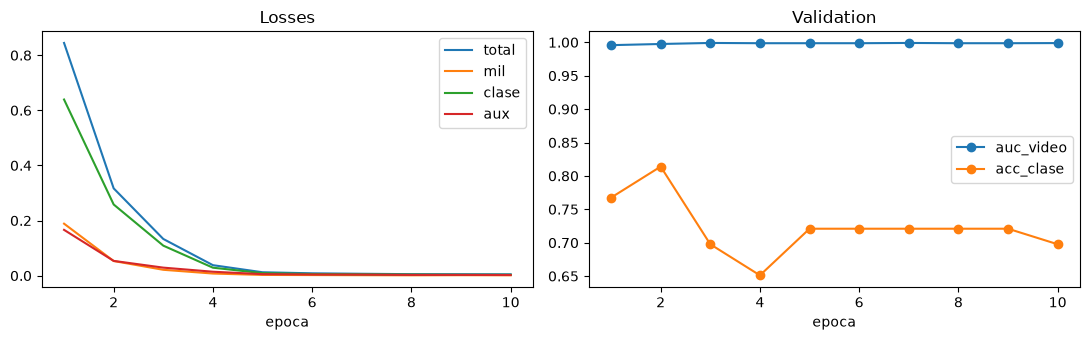

In [23]:
# 4.5 Train the main model and plot curves
model_B, hist_B = train(USE_AUX, "modelo_B")
model_B_no_aux = train(False, "modelo_B_sin_aux")[0] if (TRAIN_WITHOUT_AUX and USE_AUX) else None

h = pd.DataFrame(hist_B)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h.plot(x="epoca", y=["total", "mil", "clase", "aux"], ax=ax[0], title="Losses")
h.plot(x="epoca", y=["auc_video", "acc_clase"], ax=ax[1], title="Validation", marker="o")
plt.tight_layout(); plt.savefig(WORK / "figuras/curvas_entrenamiento.png", dpi=120); plt.show()

## 5. Evaluación de la etapa B

In [24]:
# 5.1 Predictions on the official test set
TAB = table.set_index("video")
def predict_videos(model, videos):
    return {v: predict(model, x) for v in videos if (x := get_features(v, extract=False)) is not None}
_vtest = table.video[(table.split == "test") & table.tiene_features]
PRED_TEST = predict_videos(model_B, _vtest)
print(f"{len(PRED_TEST)} test videos with predictions")

165 test videos with predictions


Frame AUC: 0.9354 · Frame AP: 0.2962


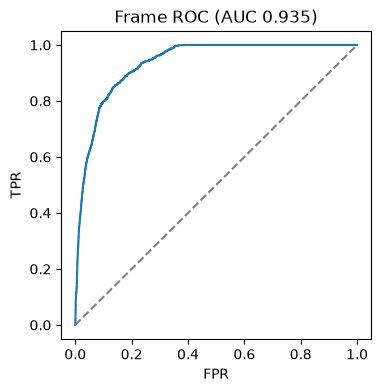

In [25]:
# 5.2 Frame level: AUC and AP
def frame_metrics(pred):
    S, G = [], []
    for v, p in pred.items():
        n = len(p["anomaly_score"]) * FRAG
        g = np.zeros(n)
        for s, e in TAB.loc[v, "gt_frames"]:
            g[s:e + 1] = 1
        S.append(np.repeat(p["anomaly_score"], FRAG)); G.append(g)
    S, G = np.concatenate(S), np.concatenate(G)
    return dict(auc=roc_auc_score(G, S), ap=average_precision_score(G, S)), S, G

frame_met, _S, _G = frame_metrics(PRED_TEST)
print(f"Frame AUC: {frame_met['auc']:.4f} · Frame AP: {frame_met['ap']:.4f}")
fpr, tpr, _ = roc_curve(_G, _S)
plt.figure(figsize=(4, 4)); plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--", c="gray")
plt.title(f"Frame ROC (AUC {frame_met['auc']:.3f})"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.savefig(WORK / "figuras/roc_frame.png", dpi=120); plt.show()
RESULTS["B_frame"] = frame_met; save_results()

Class accuracy: 0.667 (15 videos)


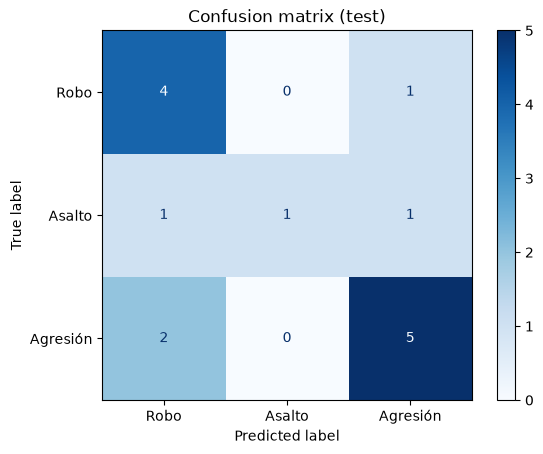

In [26]:
# 5.3 Class level: accuracy and confusion matrix (anomalous videos only)
_anom = [v for v in PRED_TEST if TAB.loc[v, "anomalo"]]
y_true = [TAB.loc[v, "clase"] for v in _anom]
y_pred = [CLASSES[int(np.argmax(PRED_TEST[v]["probs_video"][1:])) + 1] for v in _anom]
acc = float(np.mean(np.array(y_true) == np.array(y_pred))) if _anom else float("nan")
print(f"Class accuracy: {acc:.3f} ({len(_anom)} videos)")
if _anom:
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=CLASSES[1:]), display_labels=CLASSES[1:]).plot(cmap="Blues")
    plt.title("Confusion matrix (test)"); plt.savefig(WORK / "figuras/confusion_clase.png", dpi=120); plt.show()
RESULTS["B_clase"] = {"exactitud": acc, "n": len(_anom)}; save_results()

In [27]:
# 5.4 Temporal mAP per IoU threshold
def segments(m):
    m = np.r_[False, m, False].astype(int); d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

def iou_1d(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0]))
    return inter / (max(a[1], b[1]) - min(a[0], b[0]) + 1e-9)

def nms_1d(props, thr=0.7):
    out = []
    for p in sorted(props, key=lambda p: -p[-1]):
        if all(iou_1d(p[:2], q[:2]) < thr for q in out):
            out.append(p)
    return out

def proposals(pred, thresholds=np.arange(0.2, 0.95, 0.1)):
    out = defaultdict(list)
    for v, p in pred.items():
        pa = p["class_probs"][:, 1:]; pa = pa / pa.sum(1, keepdims=True)
        for ci in range(pa.shape[1]):
            sc = p["anomaly_score"] * pa[:, ci]
            cand = [(s, e, float(sc[s:e].mean() * p["probs_video"][ci + 1]))
                    for u in thresholds for s, e in segments(sc > u * sc.max())]
            out[CLASSES[ci + 1]] += [(v, *c) for c in nms_1d(cand)]
    return out

def ap_voc(tp, n_gt):
    if n_gt == 0 or not tp:
        return 0.0
    tp = np.array(tp); ctp = np.cumsum(tp); prec = ctp / np.arange(1, len(tp) + 1); rec = ctp / n_gt
    prec = np.maximum.accumulate(prec[::-1])[::-1]
    return float(np.sum(np.diff(np.r_[0, rec]) * prec))

def temporal_map(pred, ious=(0.1, 0.2, 0.3, 0.4, 0.5)):
    gts = defaultdict(list)
    for v in pred:
        if TAB.loc[v, "anomalo"]:
            gts[TAB.loc[v, "clase"]] += [(v, s // FRAG, e // FRAG + 1) for s, e in TAB.loc[v, "gt_frames"]]
    props, res = proposals(pred), {}
    for thr in ious:
        aps = []
        for c in CLASSES[1:]:
            used, tp = set(), []
            for v, s, e, sc in sorted(props[c], key=lambda p: -p[-1]):
                cand = [(iou_1d((s, e), g[1:]), k) for k, g in enumerate(gts[c]) if g[0] == v and k not in used]
                best = max(cand, default=(0, -1))
                if best[0] >= thr:
                    used.add(best[1]); tp.append(1)
                else:
                    tp.append(0)
            if gts[c]:
                aps.append(ap_voc(tp, len(gts[c])))
        res[f"IoU {thr:.1f}"] = float(np.mean(aps)) if aps else float("nan")
    res["media"] = float(np.nanmean(list(res.values())))
    return res

map_met = temporal_map(PRED_TEST)
display(pd.Series(map_met, name="mAP").round(4).to_frame().T)
RESULTS["B_mAP"] = map_met; save_results()

,IoU 0.1,IoU 0.2,IoU 0.3,IoU 0.4,IoU 0.5,media
mAP,0.0896,0.0843,0.0837,0.0487,0.0458,0.0704


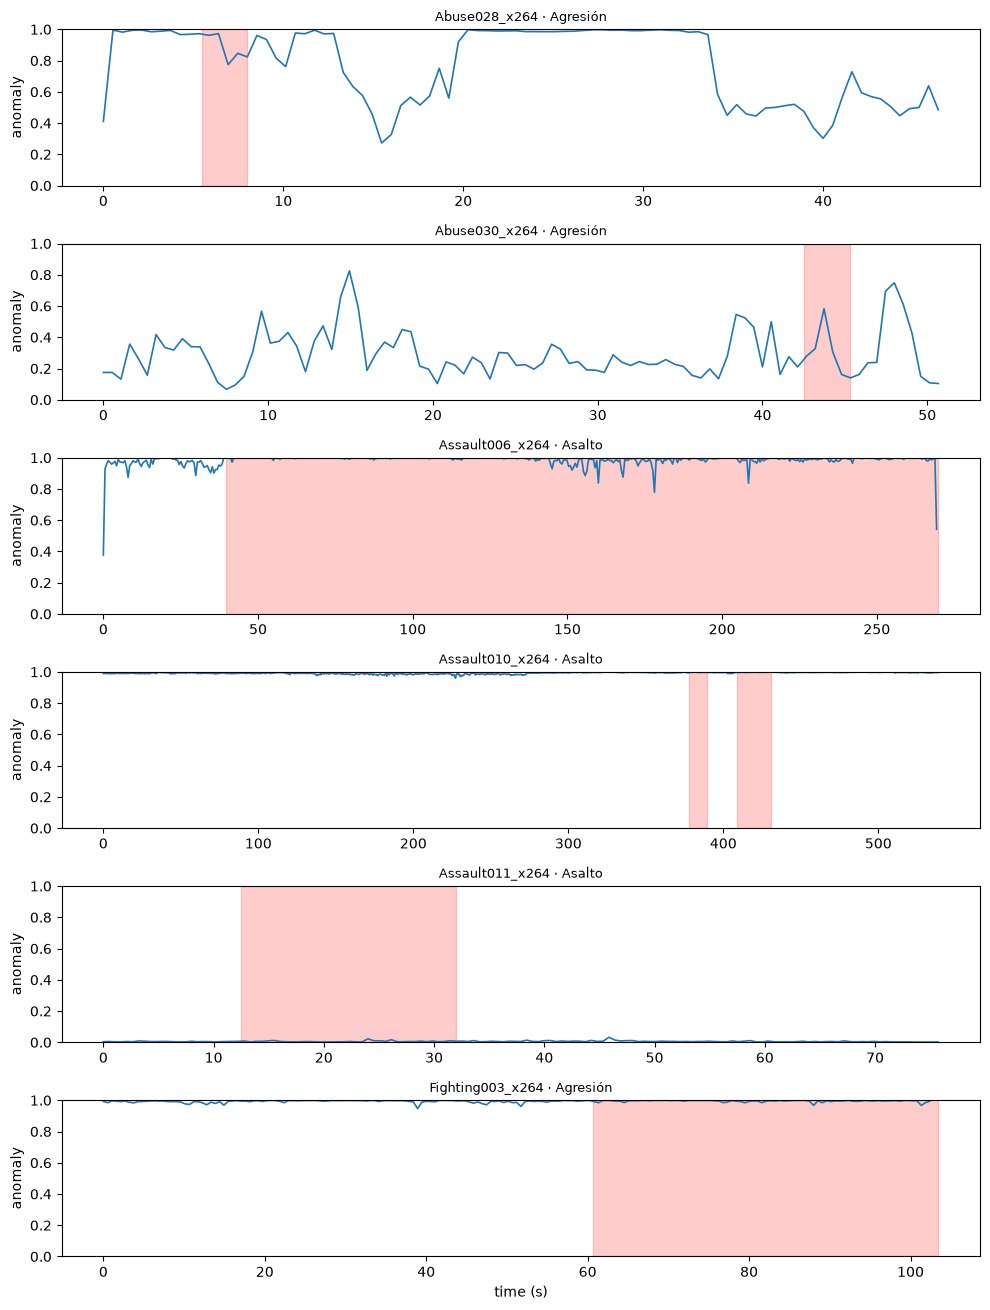

In [28]:
# 5.5 Anomaly curves per video
_show = _anom[:6]
if _show:
    fig, axs = plt.subplots(len(_show), 1, figsize=(10, 2.2 * len(_show)), squeeze=False)
    for ax, v in zip(axs[:, 0], _show):
        s, fps = PRED_TEST[v]["anomaly_score"], TAB.loc[v, "fps"]
        ax.plot(np.arange(len(s)) * FRAG / fps, s, lw=1.2)
        for a, b in TAB.loc[v, "gt_frames"]:
            ax.axvspan(a / fps, b / fps, color="red", alpha=0.2)
        ax.set_ylim(0, 1); ax.set_title(f"{v} · {TAB.loc[v, 'clase']}", fontsize=9); ax.set_ylabel("anomaly")
    axs[-1, 0].set_xlabel("time (s)")
    plt.tight_layout(); plt.savefig(WORK / "figuras/curvas_por_video.png", dpi=120); plt.show()

In [29]:
# 5.6 Ablation: with and without UCA auxiliary supervision
rows = [dict(modelo="con aux UCA", **frame_met, mAP_medio=map_met["media"], exactitud=acc)]
if model_B_no_aux is not None:
    _p = predict_videos(model_B_no_aux, _vtest)
    _m = frame_metrics(_p)[0]
    _acc = float(np.mean([CLASSES[int(np.argmax(_p[v]["probs_video"][1:])) + 1] == TAB.loc[v, "clase"] for v in _anom])) if _anom else float("nan")
    rows.append(dict(modelo="sin aux UCA", **_m, mAP_medio=temporal_map(_p)["media"], exactitud=_acc))
ABLATION_B = pd.DataFrame(rows).set_index("modelo")
display(ABLATION_B.round(4))
RESULTS["B_ablacion_aux"] = ABLATION_B.to_dict("index"); save_results()

,auc,ap,mAP_medio,exactitud
modelo,,,,
con aux UCA,0.9354,0.2962,0.0704,0.6667
sin aux UCA,0.9697,0.5191,0.1256,0.4000


## 6. Detección y tracking de personas (etapa A)

In [30]:
# 6.1 Select videos to annotate (C2 calibration and evaluation)
_sel_csv = WORK / "anotacion/seleccion.csv"
if _sel_csv.exists():
    SELECTION = pd.read_csv(_sel_csv)
else:
    cand = table[(table.anomalo == 1) & table.ruta_video.notna()].copy()
    cand["prio"] = cand.split.map({"test": 0, "val": 1, "train": 2})
    cand = cand.sort_values(["prio", "video"])
    per_class = [g.video.tolist() for _, g in cand.groupby("clase")]
    chosen = [v for group in itertools.zip_longest(*per_class) for v in group if v][:N_ANNOTATE]
    norm = table[(table.anomalo == 0) & table.ruta_video.notna() & (table.split != "train")].copy()
    norm["n_frames"] = [video_info(r)[0] for r in norm.ruta_video]
    chosen += norm.sort_values("n_frames").video.head(N_NORMAL_ANNOTATE).tolist()
    SELECTION = table.set_index("video").loc[chosen, ["clase", "split"]].reset_index()
    SELECTION["grupo"] = [("calibracion" if i % 2 == 0 else "evaluacion")
                          for i in SELECTION.groupby("clase").cumcount()]
    SELECTION.to_csv(_sel_csv, index=False)
display(pd.crosstab(SELECTION.clase, SELECTION.grupo))

grupo,calibracion,evaluacion
clase,,
Agresión,5,5
Asalto,5,5
Normal,2,2
Robo,5,5


In [31]:
# 6.2 Tracking with YOLO + ByteTrack
from ultralytics import YOLO

def track_video(path, name=None, force=False):
    name = name or Path(path).stem
    dest = WORK / "tracks" / f"{name}.csv"
    if dest.exists() and not force:
        return pd.read_csv(dest)
    model = YOLO(YOLO_MODEL)                            # fresh tracker per video
    rows = []
    for i, r in enumerate(model.track(source=str(path), stream=True, persist=True, classes=[0],
                                      conf=YOLO_CONF, imgsz=YOLO_IMGSZ, tracker=TRACKER,
                                      vid_stride=TRACKING_STRIDE, verbose=False)):
        b = r.boxes
        if b is None or b.id is None:
            continue
        for (x1, y1, x2, y2), tid, cf in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.conf.cpu().numpy()):
            rows.append((i * TRACKING_STRIDE, int(tid), x1, y1, x2, y2, float(cf)))
    df = pd.DataFrame(rows, columns=["frame", "track_id", "x1", "y1", "x2", "y2", "conf"])
    df = df[df.groupby("track_id").frame.transform("size") >= max(1, MIN_TRACK_FRAMES // TRACKING_STRIDE)]
    df.to_csv(dest, index=False)
    return df

TRACKS = {}
for v in SELECTION.video:
    TRACKS[v] = track_video(TAB.loc[v, "ruta_video"], v)
    print(f"{v}: {TRACKS[v].track_id.nunique()} people · {len(TRACKS[v])} detections")

Abuse028_x264: 2 people · 320 detections
Assault006_x264: 270 people · 22278 detections
Robbery048_x264: 13 people · 1911 detections
Abuse030_x264: 4 people · 96 detections
Assault010_x264: 183 people · 21270 detections
Robbery050_x264: 7 people · 1408 detections
Fighting003_x264: 111 people · 10351 detections
Assault011_x264: 126 people · 16338 detections
Robbery102_x264: 12 people · 958 detections
Fighting018_x264: 28 people · 3328 detections
Assault002_x264: 156 people · 7301 detections
Robbery106_x264: 10 people · 1737 detections
Fighting033_x264: 15 people · 3322 detections
Assault012_x264: 46 people · 4013 detections
Robbery137_x264: 23 people · 6172 detections
Fighting042_x264: 10 people · 2217 detections
Assault017_x264: 7 people · 248 detections
Robbery001_x264: 9 people · 1015 detections
Fighting047_x264: 147 people · 21709 detections
Assault024_x264: 42 people · 4201 detections
Robbery011_x264: 11 people · 1511 detections
Abuse008_x264: 47 people · 7719 detections
Assault029

,people,median_length,max_simultaneous,fragmentation
Abuse028_x264,2.0,160.0,1.0,2.00
Assault006_x264,270.0,48.0,8.0,33.75
Robbery048_x264,13.0,80.0,4.0,3.25
Abuse030_x264,4.0,17.0,1.0,4.00
Assault010_x264,183.0,60.0,6.0,30.50
Robbery050_x264,7.0,153.0,2.0,3.50
Fighting003_x264,111.0,55.0,9.0,12.33
Assault011_x264,126.0,61.0,16.0,7.88
Robbery102_x264,12.0,56.0,4.0,3.00
Fighting018_x264,28.0,58.0,7.0,4.00


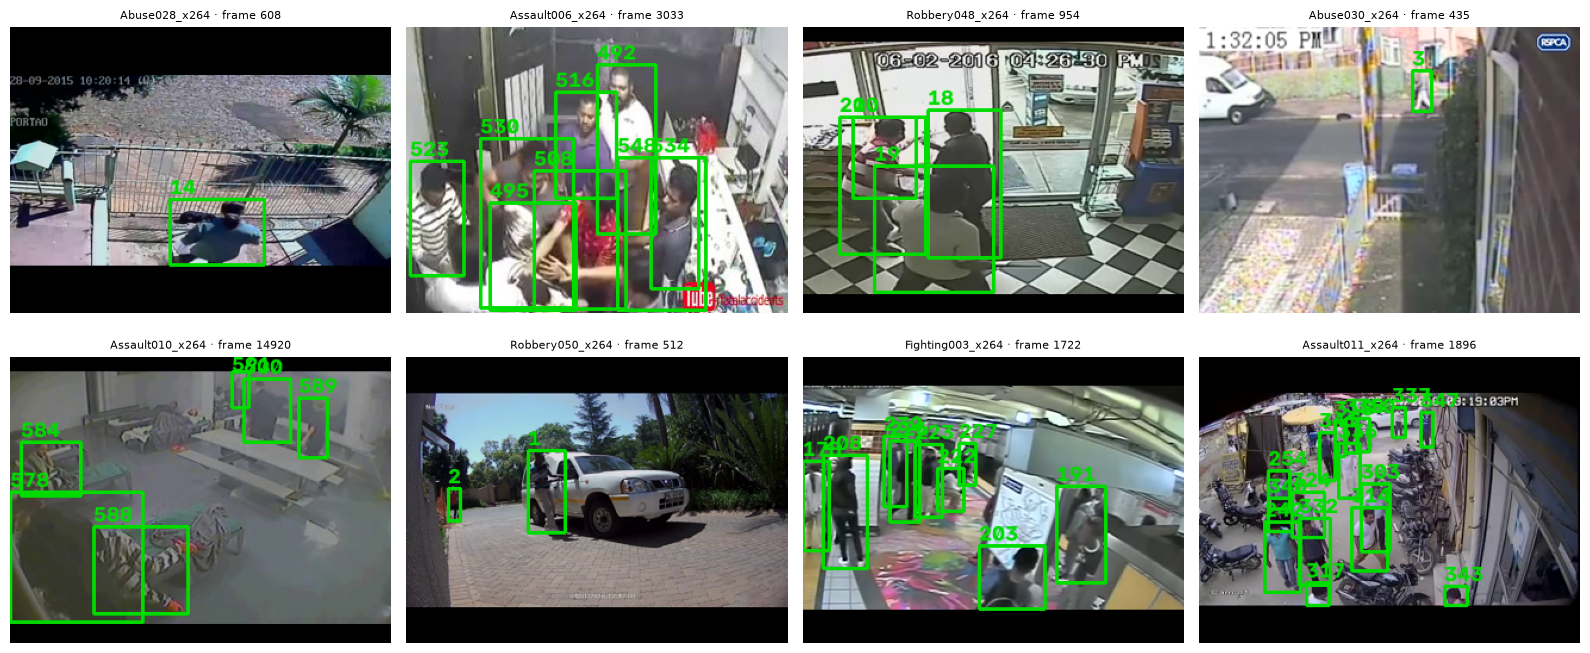

In [32]:
# 6.3 Visual review of the tracking
def draw_boxes(rgb, boxes, color=(0, 220, 0)):
    im = rgb.copy()
    for r in boxes.itertuples():
        cv2.rectangle(im, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), color, 2)
        cv2.putText(im, str(r.track_id), (int(r.x1), max(12, int(r.y1) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return im

def track_summary(tr):
    if tr.empty:
        return dict(people=0, median_length=0, max_simultaneous=0, fragmentation=np.nan)
    sim = tr.groupby("frame").size().max()
    return dict(people=tr.track_id.nunique(), median_length=int(tr.groupby("track_id").size().median()),
                max_simultaneous=int(sim), fragmentation=round(tr.track_id.nunique() / sim, 2))

display(pd.DataFrame({v: track_summary(t) for v, t in TRACKS.items()}).T)
_rev = [v for v in SELECTION.video if not TRACKS[v].empty][:8]
if _rev:
    fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
    for ax, v in zip(axs, _rev):
        tr = TRACKS[v]; f = int(tr.frame.value_counts().idxmax())
        ax.imshow(draw_boxes(read_frames(TAB.loc[v, "ruta_video"], [f])[0], tr[tr.frame == f]))
        ax.set_title(f"{v} · frame {f}", fontsize=8)
    for ax in axs:
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 7. Fusión por persona (etapa C2)

In [33]:
# 7.1 Annotation template and per-person thumbnails
ANNOT_CSV = WORK / "anotacion/anotacion_personas.csv"

def expand(x1, y1, x2, y2, w, h, f=CROP_EXPANSION):
    dx, dy = (x2 - x1) * f / 2, (y2 - y1) * f / 2
    return int(max(0, x1 - dx)), int(max(0, y1 - dy)), int(min(w, x2 + dx)), int(min(h, y2 + dy))

def thumbnails(v, tr):
    if tr.empty:
        return
    t = tr.sort_values(["track_id", "frame"])
    g = t.groupby("track_id")
    middle = t[g.cumcount() == g.frame.transform("size") // 2]
    frames = read_frames(TAB.loc[v, "ruta_video"], middle.frame.tolist())
    cells = []
    for r, fr in zip(middle.itertuples(), frames):
        h, w = fr.shape[:2]
        x1, y1, x2, y2 = expand(r.x1, r.y1, r.x2, r.y2, w, h)
        crop = fr[y1:y2, x1:x2]
        Image.fromarray(crop).save(WORK / f"anotacion/recortes/{v}_{int(r.track_id)}.jpg")
        c = cv2.resize(crop, (120, 200)); cv2.putText(c, f"ID {int(r.track_id)}", (4, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2)
        cells.append(c)
    rows = [np.hstack(cells[i:i + 8] + [np.zeros_like(cells[0])] * (8 - len(cells[i:i + 8]))) for i in range(0, len(cells), 8)]
    Image.fromarray(np.vstack(rows)).save(WORK / f"anotacion/hojas/{v}.jpg")

_rows = []
for s in SELECTION.itertuples():
    tr = TRACKS[s.video]
    thumbnails(s.video, tr)
    fps = TAB.loc[s.video, "fps"]
    gt = "; ".join(f"{a / fps:.1f}-{b / fps:.1f}s" for a, b in TAB.loc[s.video, "gt_frames"])
    for tid, g in tr.groupby("track_id"):
        _rows.append(dict(video=s.video, grupo=s.grupo, clase=s.clase, track_id=int(tid),
                          primer_seg=round(g.frame.min() / fps, 1), ultimo_seg=round(g.frame.max() / fps, 1),
                          n_frames=len(g), gt_anomalia=gt, involucrado=0 if s.clase == "Normal" else np.nan))
_template = pd.DataFrame(_rows)
if ANNOT_CSV.exists():                                  # keep existing annotations
    _prev = pd.read_csv(ANNOT_CSV)[["video", "track_id", "involucrado"]]
    _template = _template.drop(columns="involucrado").merge(_prev, on=["video", "track_id"], how="left")
    _template["involucrado"] = _template.involucrado.where(_template.clase != "Normal", 0)
if TEST_MODE:                                           # automatic annotation for the test run only
    _rank = _template.groupby("video").n_frames.rank(ascending=False, method="first")
    _template["involucrado"] = np.where(_template.clase == "Normal", 0, (_rank <= 2).astype(int))
_template.to_csv(ANNOT_CSV, index=False)
print(f"Template: {ANNOT_CSV}  ({len(_template)} people, {_template.involucrado.isna().sum()} to annotate)")
print(f"Thumbnails: {WORK / 'anotacion/hojas'}")

Template: /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/anotacion/anotacion_personas.csv  (1761 people, 1 to annotate)
Thumbnails: /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/anotacion/hojas


**Cómo anotar.** Abre `trabajo/anotacion/anotacion_personas.csv` y, para cada fila, escribe `1` en `involucrado` si esa persona participa en el evento o `0` si no. Usa la hoja `trabajo/anotacion/hojas/<video>.jpg` para reconocer cada ID y la columna `gt_anomalia` para saber cuándo ocurre el evento. Los videos normales ya vienen en `0`. Guarda el CSV y continúa con la celda 7.2.

In [34]:
# 7.2 Load and check the annotation
ANNOT = pd.read_csv(ANNOT_CSV)
_missing = ANNOT[ANNOT.involucrado.isna()]
ANNOTATION_READY = len(_missing) == 0
print(f"Annotated: {ANNOT.involucrado.notna().sum()}/{len(ANNOT)} · involved: {int(ANNOT.involucrado.sum())}")
if not ANNOTATION_READY:
    print("Still to annotate in:", ", ".join(_missing.video.unique()[:10]), "...")
    print("Calibration will use only the annotated rows.")

Annotated: 1760/1761 · involved: 808
Still to annotate in: Robbery048_x264 ...
Calibration will use only the annotated rows.


In [35]:
# 7.3 Per-person, per-fragment signals: semantics, motion and interaction
# (column names match the cached trabajo/senales/*.pkl files)
SEM_COLS = [f"sem_{c}" for c in CLASSES]

def trajectory_signals(tr):
    tr = tr.sort_values(["track_id", "frame"]).copy()
    tr["cx"], tr["cy"] = (tr.x1 + tr.x2) / 2, (tr.y1 + tr.y2) / 2
    tr["h"] = (tr.y2 - tr.y1).clip(lower=1)
    g = tr.groupby("track_id")
    dfr = g.frame.diff().fillna(1).clip(lower=1)
    tr["vel"] = (np.hypot(g.cx.diff(), g.cy.diff()) / tr.h / dfr).fillna(0)
    tr["acel"] = (tr.groupby("track_id").vel.diff().abs() / dfr).fillna(0)
    tr["dmin"], tr["iou"], tr["pareja"] = np.nan, 0.0, -1
    for _, idx in tr.groupby("frame").indices.items():
        if len(idx) < 2:
            continue
        s = tr.iloc[idx]
        c, hh = s[["cx", "cy"]].to_numpy(), s.h.to_numpy()
        D = np.linalg.norm(c[:, None] - c[None], axis=-1) / ((hh[:, None] + hh[None]) / 2)
        np.fill_diagonal(D, np.inf)
        b = s[["x1", "y1", "x2", "y2"]].to_numpy()
        iw = (np.minimum(b[:, None, 2], b[None, :, 2]) - np.maximum(b[:, None, 0], b[None, :, 0])).clip(0)
        ih = (np.minimum(b[:, None, 3], b[None, :, 3]) - np.maximum(b[:, None, 1], b[None, :, 1])).clip(0)
        area = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
        I = iw * ih / (area[:, None] + area[None] - iw * ih + 1e-9); np.fill_diagonal(I, 0)
        j = D.argmin(1)
        tr.iloc[idx, tr.columns.get_loc("dmin")] = D[np.arange(len(idx)), j]
        tr.iloc[idx, tr.columns.get_loc("iou")] = I.max(1)
        tr.iloc[idx, tr.columns.get_loc("pareja")] = s.track_id.to_numpy()[j]
    tr["acerc"] = (-tr.groupby("track_id").dmin.diff() / dfr).fillna(0).clip(lower=0)
    tr["frag"] = tr.frame // FRAG
    tr["dist_centro"] = (tr.frame - (tr.frag * FRAG + FRAG // 2)).abs()
    rep = tr.loc[tr.groupby(["track_id", "frag"]).dist_centro.idxmin(), ["track_id", "frag", "frame", "x1", "y1", "x2", "y2"]]
    agg = tr.groupby(["track_id", "frag"]).agg(vel=("vel", "mean"), acel=("acel", "max"), dmin=("dmin", "min"),
                                              iou=("iou", "max"), acerc=("acerc", "max"), h=("h", "mean"),
                                              pareja=("pareja", lambda s: int(s[s >= 0].mode().iloc[0]) if (s >= 0).any() else -1)).reset_index()
    agg = agg.merge(rep.rename(columns={"frame": "frame_rep"}), on=["track_id", "frag"])
    agg["mov"] = 1 - np.exp(-(agg.vel + 2 * agg.acel) / MOV_REF)
    agg["inter"] = np.maximum.reduce([np.exp(-agg.dmin.fillna(np.inf) / DIST_REF),
                                      (2 * agg.iou).clip(0, 1), (agg.acerc / APPROACH_REF).clip(0, 1)])
    return agg

def semantic_signal(path, agg):
    agg = agg.copy(); unique_frames = sorted(agg.frame_rep.unique())
    emb, brightness, flow = np.zeros((len(agg), DIM), np.float32), np.zeros(len(agg)), np.zeros(len(agg))
    pos = {f: np.where(agg.frame_rep.to_numpy() == f)[0] for f in unique_frames}
    for i in range(0, len(unique_frames), 64):
        block = unique_frames[i:i + 64]
        frames = read_frames(path, block)
        previous = read_frames(path, [max(0, f - 1) for f in block]) if USE_OPTICAL_FLOW else [None] * len(block)
        crops, rows = [], []
        for f, fr, fp in zip(block, frames, previous):
            h, w = fr.shape[:2]
            if fp is not None:
                fl = cv2.calcOpticalFlowFarneback(cv2.cvtColor(fp, cv2.COLOR_RGB2GRAY), cv2.cvtColor(fr, cv2.COLOR_RGB2GRAY),
                                                  None, 0.5, 3, 15, 3, 5, 1.2, 0)
                mag = np.linalg.norm(fl, axis=-1)
            for k in pos[f]:
                r = agg.iloc[k]
                x1, y1, x2, y2 = expand(r.x1, r.y1, r.x2, r.y2, w, h)
                crop = fr[y1:max(y2, y1 + 2), x1:max(x2, x1 + 2)]
                if crop.size == 0:
                    crop = np.zeros((8, 8, 3), np.uint8)
                crops.append(crop); rows.append(k); brightness[k] = crop.mean()
                if fp is not None:
                    flow[k] = mag[int(r.y1):int(r.y2), int(r.x1):int(r.x2)].mean() / max(1, r.y2 - r.y1)
        if crops:
            emb[rows] = clip_images(crops)
    cos = F.normalize(torch.tensor(emb), dim=-1).numpy() @ PERSON_TEXT_EMB.T
    for i, c in enumerate(SEM_COLS):
        agg[c] = cos[:, i]
    agg["brillo"] = brightness
    if USE_OPTICAL_FLOW:
        agg["mov"] = np.maximum(agg.mov, 1 - np.exp(-np.nan_to_num(flow) / MOV_REF))
    return agg

def compute_signals(video, path, tr, force=False):
    dest = WORK / "senales" / f"{video}.pkl"
    if dest.exists() and not force:
        return pd.read_pickle(dest)
    agg = semantic_signal(path, trajectory_signals(tr)) if not tr.empty else pd.DataFrame()
    agg.to_pickle(dest)
    return agg

def prepare_c2(video, path, tr, model=None):
    """Join per-person signals with the anomaly_score and class_probs from B."""
    model = model or model_B
    sig = compute_signals(video, path, tr)
    p = predict(model, get_features(video))
    if sig.empty:
        return sig, p
    k = sig.frag.clip(upper=len(p["anomaly_score"]) - 1).to_numpy()
    sig = sig.assign(video=video, anom=p["anomaly_score"][k])
    for i, c in enumerate(CLASSES):
        sig[f"pb_{c}"] = p["class_probs"][k, i]
    return sig.reset_index(drop=True), p

C2_DATA, PRED_SEL = {}, {}
for v in SELECTION.video:
    C2_DATA[v], PRED_SEL[v] = prepare_c2(v, TAB.loc[v, "ruta_video"], TRACKS[v])
D_C2 = pd.concat([d for d in C2_DATA.values() if len(d)], ignore_index=True)
display(D_C2[["video", "track_id", "frag", "anom", "mov", "inter"] + SEM_COLS].describe().round(3))

,track_id,frag,anom,mov,inter,sem_Normal,sem_Robo,sem_Asalto,sem_Agresión
count,15799.000,15799.000,15799.000,15799.000,15799.000,15799.000,15799.000,15799.000,15799.000
mean,309.305,208.802,0.736,0.446,0.681,0.248,0.261,0.247,0.210
std,371.548,214.863,0.410,0.288,0.338,0.018,0.016,0.012,0.019
min,1.000,0.000,0.000,0.000,0.000,0.174,0.199,0.185,0.144
25%,49.000,62.000,0.354,0.191,0.478,0.236,0.249,0.239,0.197
50%,196.000,132.000,0.989,0.420,0.743,0.249,0.263,0.246,0.212
75%,399.000,283.000,0.997,0.688,1.000,0.261,0.274,0.254,0.224
max,1789.000,1011.000,1.000,1.000,1.000,0.301,0.342,0.312,0.299


In [36]:
# 7.4 Decision rule (C2) and C1 baseline
def decide(D, p, mode="C2"):
    D = D.copy().reset_index(drop=True)
    A = D[[f"pb_{c}" for c in CLASSES[1:]]].to_numpy(); A = A / A.sum(1, keepdims=True)
    cb = A.argmax(1)
    cos = D[SEM_COLS].to_numpy()
    D["sem"] = 1 / (1 + np.exp(-100 * (cos[np.arange(len(D)), cb + 1] - cos[:, 0])))
    ws, wm, wi = p["w_sem"], p["w_mov"], p["w_inter"] * p["refuerzo_inter"]
    D["score"] = (ws * D["sem"] + wm * D["mov"] + wi * D["inter"]) / max(ws + wm + wi, 1e-9)
    D["active"] = D.anom > p["umbral_global"]
    if mode == "C1":
        D["red"] = D.active
    else:
        D["red"] = D.active & (D.score > p["umbral_ind"])
        # interacting pairs
        pair = D.loc[D.red & (D.inter > p["umbral_pareja"]), ["video", "frag", "pareja"]].drop_duplicates()
        if len(pair):
            key = set(zip(pair.video, pair.frag, pair.pareja))
            D.loc[D.active & pd.Series([k in key for k in zip(D.video, D.frag, D.track_id)]), "red"] = True
        # fallback: clear event with nobody in red
        clear = D[D.anom > p["umbral_claro"]]
        if len(clear):
            nobody = clear.groupby(["video", "frag"]).red.transform("any") == False
            if nobody.any():
                D.loc[clear[nobody].groupby(["video", "frag"]).score.idxmax().to_numpy(), "red"] = True
    # displayed class: B corrected by the person's CLIP embedding
    ps = np.exp(100 * (cos[:, 1:] - cos[:, 1:].max(1, keepdims=True))); ps /= ps.sum(1, keepdims=True)
    mix = (1 - p["alfa_clase"]) * A + p["alfa_clase"] * ps
    D["pred_class"] = np.array(CLASSES[1:])[mix.argmax(1)]
    D["class_prob"] = mix.max(1)
    return D

In [37]:
# 7.5 Person-level evaluation
def evaluate_people(D, annot, videos):
    pred = (D[D.video.isin(videos)].groupby(["video", "track_id"]).red.sum() >= MIN_RED_FRAGS).rename("pred").reset_index()
    m = annot[annot.video.isin(videos) & annot.involucrado.notna()].merge(pred, on=["video", "track_id"], how="left")
    m["pred"] = m.pred.fillna(False).astype(int)
    if m.empty:
        return dict(precision=np.nan, recall=np.nan, f1=0.0, n=0), m
    p, r, f, _ = precision_recall_fscore_support(m.involucrado.astype(int), m.pred, average="binary", zero_division=0)
    return dict(precision=p, recall=r, f1=f, n=len(m)), m

In [38]:
# 7.6 Grid-search calibration (person-level F1)
CAL_VIDEOS = SELECTION.video[SELECTION.grupo == "calibracion"].tolist()
EVAL_VIDEOS = SELECTION.video[SELECTION.grupo == "evaluacion"].tolist()
_WEIGHTS = [t for t in itertools.product(np.arange(0, 1.01, 0.25), repeat=3) if abs(sum(t) - 1) < 1e-6]
GRID = dict(umbral_global=[0.3, 0.4, 0.5, 0.6, 0.7], umbral_ind=[0.3, 0.4, 0.5, 0.6, 0.7],
            weights=_WEIGHTS, refuerzo_inter=[1.0, 1.5, 2.0])

def calibrate(D, annot, videos, mode="C2", without=None):
    base, best, best_f1 = dict(PARAMS_C2), dict(PARAMS_C2), -1
    weights = [w for w in GRID["weights"] if without is None or w[["sem", "mov", "inter"].index(without)] == 0]
    if mode == "C1":
        combos = [(ug, base["umbral_ind"], (base["w_sem"], base["w_mov"], base["w_inter"]), 1.0) for ug in GRID["umbral_global"]]
    else:
        combos = itertools.product(GRID["umbral_global"], GRID["umbral_ind"], weights, GRID["refuerzo_inter"])
    Dv = D[D.video.isin(videos)]
    for ug, ui, (ws, wm, wi), ri in combos:
        p = dict(base, umbral_global=ug, umbral_ind=ui, w_sem=ws, w_mov=wm, w_inter=wi, refuerzo_inter=ri)
        f1 = evaluate_people(decide(Dv, p, mode), annot, videos)[0]["f1"]
        if f1 > best_f1:
            best, best_f1 = p, f1
    return best, best_f1

PARAMS_CAL, _f1 = calibrate(D_C2, ANNOT, CAL_VIDEOS)
PARAMS_C1, _ = calibrate(D_C2, ANNOT, CAL_VIDEOS, mode="C1")
print(f"C2 calibration F1: {_f1:.3f}")
display(pd.Series(PARAMS_CAL).to_frame("value").T)
(WORK / "params_c2.json").write_text(json.dumps(PARAMS_CAL, indent=2, default=float))

C2 calibration F1: 0.723


,umbral_global,umbral_ind,w_sem,w_mov,w_inter,refuerzo_inter,umbral_pareja,umbral_claro,alfa_clase
value,0.7,0.5,0.25,0.5,0.25,1.5,0.6,0.8,0.3


192

,precision,recall,f1,n
config,,,,
C1 (all in red),0.429,0.963,0.593,698
C2 full,0.425,0.859,0.568,698
C2 without semantics,0.422,0.881,0.570,698
C2 without motion,0.438,0.941,0.597,698
C2 without interaction,0.428,0.903,0.581,698


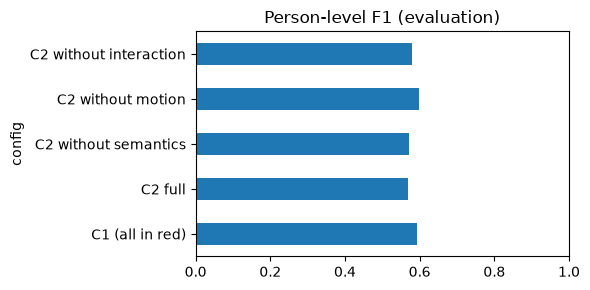

In [39]:
# 7.7 Evaluation: C2 vs C1 and signal ablation
rows = [dict(config="C1 (all in red)", **evaluate_people(decide(D_C2, PARAMS_C1, "C1"), ANNOT, EVAL_VIDEOS)[0]),
        dict(config="C2 full", **evaluate_people(decide(D_C2, PARAMS_CAL), ANNOT, EVAL_VIDEOS)[0])]
for s, name in [("sem", "without semantics"), ("mov", "without motion"), ("inter", "without interaction")]:
    p_s = calibrate(D_C2, ANNOT, CAL_VIDEOS, without=s)[0]
    rows.append(dict(config=f"C2 {name}", **evaluate_people(decide(D_C2, p_s), ANNOT, EVAL_VIDEOS)[0]))
C2_TABLE = pd.DataFrame(rows).set_index("config")
display(C2_TABLE.round(3))
C2_TABLE.f1.plot.barh(figsize=(6, 3), title="Person-level F1 (evaluation)"); plt.xlim(0, 1)
plt.tight_layout(); plt.savefig(WORK / "figuras/c2_ablacion.png", dpi=120); plt.show()
RESULTS["C2_persona"] = C2_TABLE.to_dict("index"); save_results()

,video,track_id,type,cause,score_max,red_frags,clase,class_B
469,Robbery019_x264,1,FP,innocent sudden motion,0.980978,5,Robo,Robo
471,Robbery019_x264,15,FP,innocent sudden motion,0.980207,16,Robo,Robo
414,Abuse008_x264,1,FP,innocent sudden motion,0.974359,32,Agresión,Agresión
473,Robbery019_x264,22,FP,innocent sudden motion,0.973919,2,Robo,Robo
472,Robbery019_x264,20,FP,innocent sudden motion,0.965369,12,Robo,Robo
680,Robbery026_x264,1026,FP,innocent sudden motion,0.963416,7,Robo,Robo
440,Abuse008_x264,92,FP,innocent sudden motion,0.953635,4,Agresión,Agresión
439,Abuse008_x264,91,FP,innocent sudden motion,0.952648,2,Agresión,Agresión
161,Assault010_x264,578,FP,"class confusion in B, innocent sudden motion",0.945211,13,Asalto,Agresión
452,Abuse008_x264,128,FP,innocent sudden motion,0.944366,11,Agresión,Agresión


n
type cause                                                  
FN   class confusion in B                                 20
     other                                                11
     small or occluded person                              3
     small or occluded person, class confusion in B        4
FP   class confusion in B                                 26
     class confusion in B, innocent sudden motion        182
     innocent sudden motion                               69
     night scene, innocent sudden motion                   4
     other                                                19
     small or occluded person                              4
     small or occluded person, class confusion in B        1
     small or occluded person, class confusion in B,...    7
     small or occluded person, innocent sudden motion      1

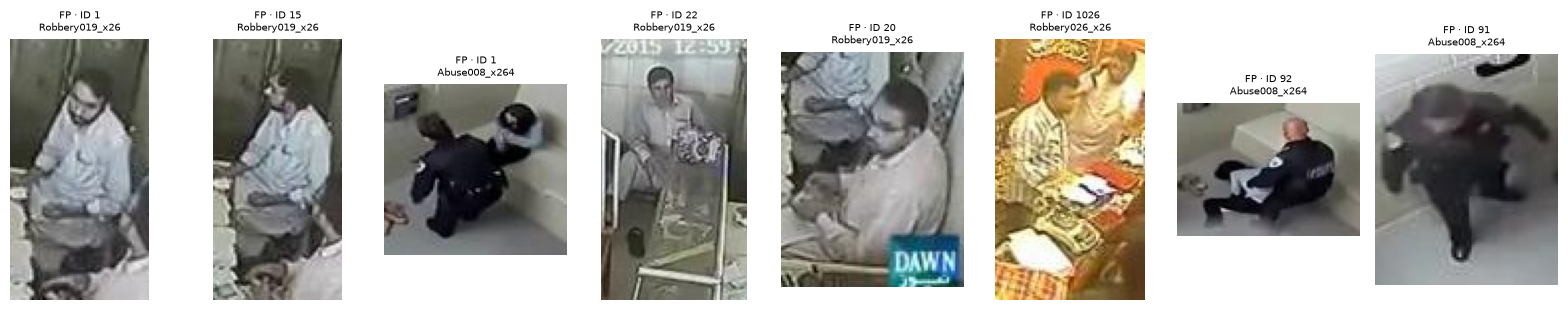

In [40]:
# 7.8 Error analysis (false positives and negatives)
D_eval = decide(D_C2, PARAMS_CAL)
_, M = evaluate_people(D_eval, ANNOT, EVAL_VIDEOS)
st = D_eval.groupby(["video", "track_id"]).agg(h=("h", "mean"), brightness=("brillo", "mean"), mov_max=("mov", "max"),
                                                score_max=("score", "max"), red_frags=("red", "sum")).reset_index()
M = M.merge(st, on=["video", "track_id"], how="left")
M["frame_height"] = M.video.map(lambda v: video_info(TAB.loc[v, "ruta_video"])[3])
M["class_B"] = M.video.map(lambda v: CLASSES[int(np.argmax(PRED_SEL[v]["probs_video"][1:])) + 1])

def causes(r):
    c = []
    if r.h / max(r.frame_height, 1) < 0.12: c.append("small or occluded person")
    if r.brightness < 60: c.append("night scene")
    if r.clase != "Normal" and r.class_B != r.clase: c.append("class confusion in B")
    if r.pred and not r.involucrado and r.mov_max > 0.6: c.append("innocent sudden motion")
    return ", ".join(c) or "other"

ERR = M[M.pred != M.involucrado.astype(int)].copy()
ERR["type"] = np.where(ERR.pred == 1, "FP", "FN")
ERR["cause"] = ERR.apply(causes, axis=1)
ERR = ERR.sort_values("score_max", key=lambda s: np.where(ERR.type == "FP", -s, s))
display(ERR[["video", "track_id", "type", "cause", "score_max", "red_frags", "clase", "class_B"]].head(15))
display(ERR.groupby(["type", "cause"]).size().rename("n").to_frame())
_top = ERR.head(8)
if len(_top):
    fig, axs = plt.subplots(1, len(_top), figsize=(2 * len(_top), 3.2), squeeze=False)
    for ax, r in zip(axs[0], _top.itertuples()):
        f = WORK / f"anotacion/recortes/{r.video}_{r.track_id}.jpg"
        if f.exists(): ax.imshow(Image.open(f))
        ax.set_title(f"{r.type} · ID {r.track_id}\n{r.video[:14]}", fontsize=7); ax.axis("off")
    plt.tight_layout(); plt.show()

## 8. Demo: pipeline completo con salida MP4 (etapa D)

In [ ]:
# 8.1 Temporal smoothing: exponential moving average + hysteresis
def smooth(D):
    D = D.sort_values(["track_id", "frag"]).copy()
    ema_col, on_col = np.zeros(len(D)), np.zeros(len(D), bool)
    for _, idx in D.groupby("track_id").indices.items():
        ema, on, c_on, c_off = 0.0, False, 0, 0
        for i in idx:
            r = D.iloc[i]
            risk = r.score if r.active else 0.0
            if r.red:
                risk = max(risk, THR_ON + 1e-3)
            ema = EMA_ALPHA * risk + (1 - EMA_ALPHA) * ema
            if not on:
                c_on = c_on + 1 if ema > THR_ON else 0
                if c_on >= N_ON: on, c_off = True, 0
            else:
                c_off = c_off + 1 if ema < THR_OFF else 0
                if c_off >= N_OFF: on, c_on = False, 0
            ema_col[i], on_col[i] = ema, on
    D["ema"], D["danger"] = ema_col, on_col
    return D

In [42]:
# 8.2 Drawing with OpenCV and writing the video
_FONT_PATH = matplotlib.font_manager.findfont("DejaVu Sans:bold")
GREEN, RED = (0, 200, 0), (0, 0, 255)                        # BGR

def num(x):
    return f"{x:.2f}"

def draw_video(path, tracks, D, pred, output):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or DEFAULT_FPS
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    font = ImageFont.truetype(_FONT_PATH, max(12, h // 38))
    tmp = str(output) + ".tmp.mp4"
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    per_frame = {f: g for f, g in tracks.groupby("frame")}
    state = {(r.track_id, r.frag): r for r in D.itertuples()} if len(D) else {}
    anom, probs = pred["anomaly_score"], pred["class_probs"]
    f, last = 0, None
    while True:
        ok, im = cap.read()
        if not ok:
            break
        boxes = per_frame.get(f, last if TRACKING_STRIDE > 1 else None)
        last = boxes if boxes is not None else last
        k = min(f // FRAG, len(anom) - 1)
        labels = []
        if boxes is not None:
            for r in boxes.itertuples():
                e = state.get((r.track_id, f // FRAG))
                is_red = bool(e is not None and e.danger)
                col = RED if is_red else GREEN
                cv2.rectangle(im, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), col, 2)
                txt = f"{e.pred_class} {num(e.class_prob)} · ID {r.track_id}" if is_red else f"ID {r.track_id}"
                labels.append((int(r.x1), int(r.y1), txt, col))
        frag_class = CLASSES[int(np.argmax(probs[k][1:])) + 1]
        banner = f"Anomaly {num(anom[k])} · {frag_class}" if anom[k] > PARAMS_USE["umbral_global"] else f"Anomaly {num(anom[k])} · Normal"
        pil = Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); dr = ImageDraw.Draw(pil)
        height = font.size + 10
        dr.rectangle([0, 0, w, height], fill=(170, 30, 30) if anom[k] > PARAMS_USE["umbral_global"] else (40, 40, 40))
        dr.text((8, 4), banner, font=font, fill=(255, 255, 255))
        for x, y, txt, col in labels:
            tw = dr.textlength(txt, font=font); y0 = max(height, y - font.size - 6)
            x = int(max(0, min(x, w - tw - 6)))
            dr.rectangle([x, y0, x + tw + 6, y0 + font.size + 4], fill=col[::-1])
            dr.text((x + 3, y0 + 1), txt, font=font, fill=(255, 255, 255))
        vw.write(cv2.cvtColor(np.asarray(pil), cv2.COLOR_RGB2BGR))
        f += 1
    cap.release(); vw.release()
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", tmp, "-c:v", "libx264", "-pix_fmt", "yuv420p",
                    "-movflags", "+faststart", str(output)], check=True)
    os.remove(tmp)
    return output

def plot_anomaly(name, pred, fps, gt_frames=(), thr=None):
    s = pred["anomaly_score"]
    plt.figure(figsize=(10, 2.4)); plt.plot(np.arange(len(s)) * FRAG / fps, s, lw=1.3)
    for a, b in gt_frames:
        plt.axvspan(a / fps, b / fps, color="red", alpha=0.2, label="ground-truth interval")
    if thr is not None:
        plt.axhline(thr, ls="--", c="gray", lw=1)
    plt.ylim(0, 1); plt.xlabel("time (s)"); plt.ylabel("anomaly"); plt.title(name)
    plt.tight_layout(); plt.savefig(WORK / f"demo/{name}_curva.png", dpi=120); plt.show()

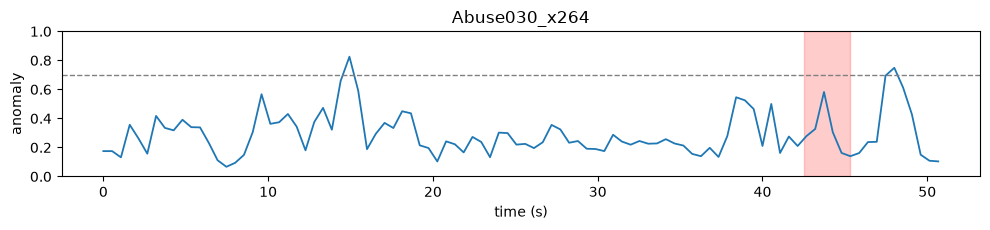

/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/demo/Abuse030_x264_C2.mp4


In [43]:
# 8.3 Full pipeline on one video
PARAMS_USE = json.loads((WORK / "params_c2.json").read_text()) if (WORK / "params_c2.json").exists() else dict(PARAMS_C2)

def process_video(path, mode="C2", params=None, show=True):
    params = params or (PARAMS_USE if mode == "C2" else PARAMS_C1)
    name = Path(path).stem
    if name not in VIDEO_IDX:
        VIDEO_IDX[name] = str(path)
    tr = track_video(path, name)                                     # A
    D, pred = prepare_c2(name, path, tr)                             # B + signals
    D = smooth(decide(D, params, mode)) if len(D) else D             # C2 + smoothing
    output = draw_video(path, tr, D, pred, WORK / f"demo/{name}_{mode}.mp4")   # D
    if show:
        fps = video_info(path)[1]
        gt = TAB.loc[name, "gt_frames"] if name in TAB.index else []
        plot_anomaly(name, pred, fps, gt, params["umbral_global"])
        display(Video(str(output), embed=True, width=720))
    return output, D

_demo = DEMO_VIDEOS or [TAB.loc[v, "ruta_video"] for v in EVAL_VIDEOS[:1]]
for path in _demo:
    print(process_video(path)[0])

In [44]:
# 8.4 Visual comparison C1 vs C2 (optional)
COMPARE_C1 = False
if COMPARE_C1 and _demo:
    process_video(_demo[0], mode="C1")

## 9. Conclusiones y limitaciones

In [45]:
# 9.1 Metrics summary
print(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))

{
  "B_frame": {
    "auc": 0.935399836091952,
    "ap": 0.2961657723095298
  },
  "B_clase": {
    "exactitud": 0.6666666666666666,
    "n": 15
  },
  "B_mAP": {
    "IoU 0.1": 0.08961159884298643,
    "IoU 0.2": 0.08427931716231152,
    "IoU 0.3": 0.08365879086874789,
    "IoU 0.4": 0.04867463984036154,
    "IoU 0.5": 0.0457928254416932,
    "media": 0.07040343443122012
  },
  "B_ablacion_aux": {
    "con aux UCA": {
      "auc": 0.935399836091952,
      "ap": 0.2961657723095298,
      "mAP_medio": 0.07040343443122012,
      "exactitud": 0.6666666666666666
    },
    "sin aux UCA": {
      "auc": 0.9696657050142431,
      "ap": 0.5190561134137976,
      "mAP_medio": 0.12564807897431096,
      "exactitud": 0.4
    }
  },
  "C2_persona": {
    "C1 (all in red)": {
      "precision": 0.4288079470198676,
      "recall": 0.9628252788104089,
      "f1": 0.5933562428407789,
      "n": 698
    },
    "C2 full": {
      "precision": 0.42463235294117646,
      "recall": 0.8587360594795539,
   

**Conclusiones** (completar con los resultados):

- Etapa B: AUC y AP a nivel de frame frente a VadCLIP; efecto de la supervisión auxiliar UCA.
- Clasificación: clases que más se confunden según la matriz de confusión.
- C2 frente a C1: ganancia en F1 por persona y señal que más aporta según la ablación.

**Limitaciones**

- Pocos videos de test por clase en el subconjunto (las métricas de clase tienen alta varianza).
- Verdad por persona anotada a mano en un conjunto pequeño.
- Personas pequeñas u ocluidas y escenas nocturnas degradan detección y señal semántica.
- Las etiquetas UCA son ruidosas; el filtro por verbos es heurístico.